In [1]:
from jax import config
config.update("jax_enable_x64", True)
import jax
import jax.numpy as jnp
from jax import grad, jit, vmap, lax

import numpy as np
import sys, os
import matplotlib.pyplot as plt

from functools import partial
import petitRADTRANS.physical_constants as cst
#import petitRADTRANS.fortran_radtrans_core import math as fmath
import petitRADTRANS.jax_physics as jphys
import petitRADTRANS.jax_math as jmath
import petitRADTRANS.jax_test_feautrier as fj
import petitRADTRANS.jax_radtrans as jr



import petitRADTRANS.physical_constants as cst 
from petitRADTRANS.fortran_radtrans_core import fortran_radtrans_core as fs
from petitRADTRANS.fortran_radtrans_core import math, cloud_utils, physics
from petitRADTRANS.radtrans import Radtrans
from petitRADTRANS.retrieval.parameter import Parameter
from petitRADTRANS.retrieval.models import emission_model_diseq, guillot_emission
import petitRADTRANS.plotlib.style as ps
ps.set_petitradtrans_plot_style()
path_input_data = "/Users/nasedkin/testing/input_data/"
# Physical and mathematical constants (assuming they are available)
# e.g., from a constants module or passed as arguments
CST_PI = jnp.pi # Or the specific precision from Fortran
TINIEST = jnp.finfo(jnp.float64).tiny
HUGE_SQRT = jnp.sqrt(jnp.finfo(jnp.float64).max)

Using pRT Plotting style!


In [2]:
path_input_data = "/Users/nasedkin/python-packages/petitRADTRANS/input_data/"
buffer = np.genfromtxt(os.path.join(path_input_data, 'opa_input_files', 'g_comb_grid.dat'))
mu_points = np.genfromtxt(os.path.join(path_input_data, 'opa_input_files', 'mu_points.dat'))

N_pressures = 20
N_frequency = 50
N_species = 2
N_ckg = 16

gravity = 10**4

pressure_unit = 1e6
pressures = 1e6*np.logspace(-6,3,N_pressures)

wavelength_min = 1.0
wavelength_max = 5.0
micron_to_meter = 1e-4

jax_pressures = 1e6*jnp.logspace(-6,3,20)
jax_gravity = 10**4
jax_total_opacity = jnp.ones((N_ckg,N_frequency,N_species,N_pressures))
jax_total_opacity_transpose = jnp.ones((N_ckg,N_frequency,N_species,N_pressures)).T
jax_continuum_opacities = jnp.ones((N_frequency,N_pressures))
jax_frequency_bin_edges = cst.c/(jnp.linspace(wavelength_min,wavelength_max,N_frequency+1)*micron_to_meter)
jax_frequency_bin_centers = (jax_frequency_bin_edges[:-1]+jax_frequency_bin_edges[1:])*0.5
jax_wgauss = jnp.array(buffer[:,1])

line_opacities_grid = np.ones((N_ckg,N_frequency,N_species,N_pressures))
line_opacities_transpose = np.ones((N_ckg,N_frequency,N_species,N_pressures)).T
continuum_opacities_grid = np.ones((N_pressures,N_frequency))
continuum_opacities_transpose = continuum_opacities_grid.T
frequency_bin_edges = cst.c/(np.linspace(wavelength_min,wavelength_max,N_frequency+1)*micron_to_meter)
frequency_bin_centers = (frequency_bin_edges[:-1]+frequency_bin_edges[1:])*0.5
w_gauss = buffer[:,1]


Test test_compute_feautrier_radiative_transfer_wrapper passed with emission_geometry='planetary_ave'.


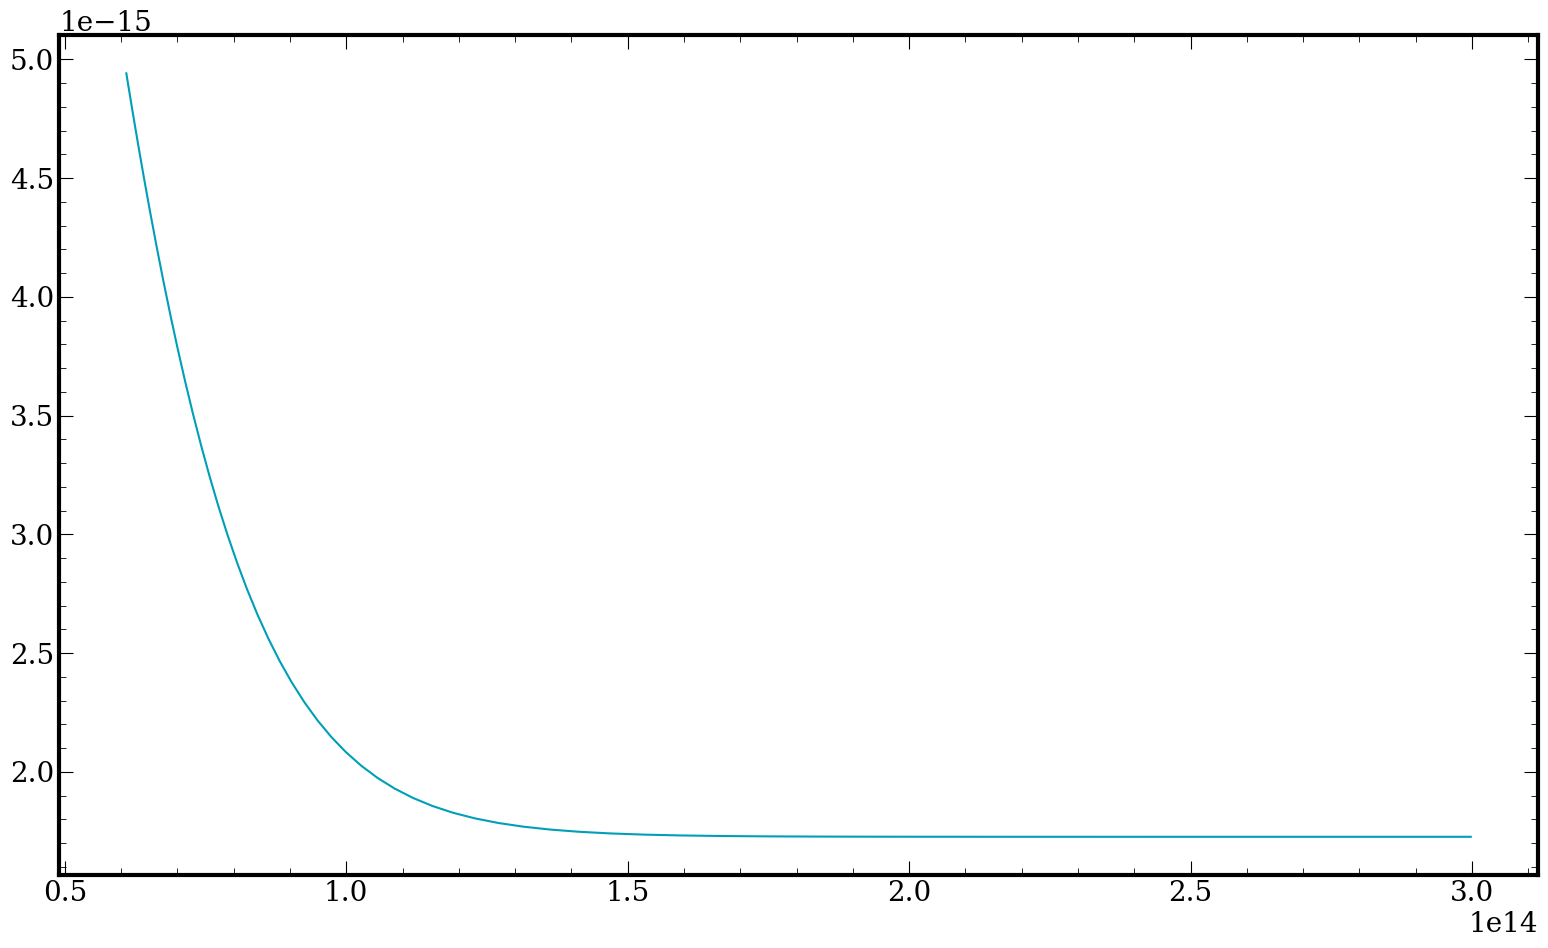

In [3]:
def test_compute_feautrier_radiative_transfer_wrapper():
    """
    Tests the Python wrapper for the compute_feautrier_radiative_transfer Fortran subroutine.
    It checks for correct output shapes, types, and basic data integrity.
    """
    # Define dimensions for the test
    n_layers = 5
    n_freq_bins = 10
    n_frequencies_bin_edges = n_freq_bins + 1
    n_angles = 3  # Number of emission angles for quadrature
    n_g = 16       # Number of Gauss quadrature points for c-k opacity treatment

    # --- Create Input Arrays ---
    # Ensure float64 for Fortran double precision and Fortran memory order for f2py.

    # frequencies_bin_edges(n_frequencies_bin_edges)
    # Note: compute_planck_function_integral expects frequencies in decreasing order.
    frequencies_bin_edges = jnp.linspace(1e14, 1e13, n_frequencies_bin_edges)

    # temperatures(n_layers)
    temperatures = jnp.linspace(500., 2500., n_layers)

    # weights_gauss(n_g)
    weights_gauss = jnp.array(buffer[:,1]) # Simple equal weights

    # emission_cos_angles(n_angles)
    emission_cos_angles = jnp.array(mu_points[:,0]) # mu values

    # emission_cos_angles_weights(n_angles)
    emission_cos_angles_weights = jnp.array(mu_points[:,1])

    # optical_depths(n_g, n_freq_bins, n_layers)
    optical_depths = jnp.abs(jnp.ones((n_g, n_freq_bins, n_layers)) 
                             *jnp.logspace(-5,-3,n_g)[:,None,None]
                             *jnp.logspace(-5,-3,n_freq_bins)[None,:,None]
                             *jnp.logspace(-5,-3,n_layers)[None,None,:]).astype(jnp.float64)

    # photon_destruction_probabilities(n_g, n_freq_bins, n_layers)
    # Values typically between 1e-10 and 1.0.
    photon_destruction_probabilities = jnp.abs(jnp.ones((n_g, n_freq_bins, n_layers))*1e-5).astype(jnp.float64)
                                              # *jnp.logspace(-8,-6,n_g)[:,None,None]
                                              # *jnp.logspace(-8,-6,n_freq_bins)[None,:,None]
                                              # *jnp.logspace(-8,-6,n_layers)[None,None,:]).astype(jnp.float64)

    # emission_geometry (string)
    emission_geometry = "dayside_ave"  # Other options: 'planetary_ave', 'non-isotropic'

    # stellar_intensity(n_freq_bins)
    stellar_intensity = jnp.zeros(n_freq_bins)

    # star_irradiation_cos_angle (scalar double precision)
    star_irradiation_cos_angle = jnp.float64(1.0) # Example value

    # reflectances(n_freq_bins)
    reflectances = jnp.zeros(n_freq_bins)

    # emissivities(n_freq_bins)
    emissivities = jnp.ones(n_freq_bins)*0.1

    # return_contribution (logical)
    return_contribution = False

    # --- Call the Fortran subroutine ---
    # The f2py wrapper returns the 'intent(out)' arguments.
    # Order of arguments must match the Fortran subroutine definition.

    n_layers = 20
    n_freq_bins = 50
    n_frequencies_bin_edges = 50+1
    N_species = 2
    n_g = 16
    n_angles = 3
    wavelength_min = 1.0
    wavelength_max = 5.0
    micron_to_meter = 1e-4

    pressure_unit = 1e6
    pressures = 1e6*jnp.logspace(-6,3,N_pressures)
    frequencies_bin_edges = cst.c/(jnp.linspace(wavelength_min,wavelength_max,n_frequencies_bin_edges)*micron_to_meter)
    frequency_bin_centers = (frequency_bin_edges[:-1]+frequency_bin_edges[1:])*0.5
    temperatures = jnp.ones(pressures.shape[0])*500
    weights_gauss = jnp.array(buffer[:,1])
    emission_cos_angles = jnp.array([0.1127,0.5,0.88729])
    emission_cos_angles_weights = jnp.array([0.2777777,0.444444444,0.2777777777])
    optical_depths = jnp.ones((n_g, n_freq_bins, N_pressures))
                    # * jnp.sin(jnp.linspace(0.01,10,n_g))[:,None,None]
                    # * jnp.cos(jnp.linspace(0.1,10,n_freq_bins))[None,:,None]
                    # * jnp.sin(jnp.linspace(0.3,5,N_pressures))[None,None,:]
                    # * 1e-4)
    photon_destruction_probabilities = np.ones((n_g, n_freq_bins, N_pressures))#*1e-5* jnp.linspace(0.1,10,n_freq_bins)[None,:,None]
    emission_geometry = 'planetary_ave'
    stellar_intensity = jnp.ones(n_freq_bins)*1e-7
    star_irradiation_cos_angle = 0.5  
    reflectances = jnp.ones(n_freq_bins)*1e-7
    emissivities = jnp.ones(n_freq_bins)*1e-7
    return_contribution = False
    
    flux_out, emission_contribution_out = \
        fs.compute_feautrier_radiative_transfer(
            frequencies_bin_edges,
            temperatures,
            weights_gauss,
            emission_cos_angles,
            emission_cos_angles_weights,
            optical_depths,
            photon_destruction_probabilities,
            emission_geometry,
            stellar_intensity,
            star_irradiation_cos_angle,
            reflectances,
            emissivities,
            return_contribution,
            n_frequencies_bin_edges, # Integer dimension
            n_layers,                # Integer dimension
            n_angles,                # Integer dimension
            n_g                      # Integer dimension
        )
    plt.plot(frequencies_bin_edges[:-1], flux_out)
    # --- Assertions ---
    # Check flux output
    assert flux_out.shape == (n_freq_bins,), \
        f"Flux output shape mismatch: expected ({n_freq_bins},), got {flux_out.shape}"
    assert flux_out.dtype == np.float64, \
        f"Flux output dtype mismatch: expected np.float64, got {flux_out.dtype}"
    assert not np.any(np.isnan(flux_out)), "NaNs found in flux_out"
    assert not np.any(np.isinf(flux_out)), "Infs found in flux_out"
    # Flux should generally be non-negative for emission spectra
    assert np.all(flux_out >= -1e-9), \
        "Negative values (beyond tolerance) found in flux_out, which might be unexpected for emission."


    # Check emission_contribution output
    if return_contribution:
        assert emission_contribution_out.shape == (n_layers, n_freq_bins), \
            f"Emission contribution output shape mismatch: " \
            f"expected ({n_layers}, {n_freq_bins}), got {emission_contribution_out.shape}"
        assert emission_contribution_out.dtype == np.float64, \
            f"Emission contribution output dtype mismatch: " \
            f"expected np.float64, got {emission_contribution_out.dtype}"
        assert not np.any(np.isnan(emission_contribution_out)), \
            "NaNs found in emission_contribution_out"
        assert not np.any(np.isinf(emission_contribution_out)), \
            "Infs found in emission_contribution_out"

        # The Fortran code normalizes emission_contribution per frequency:
        # emission_contribution(:,i_freq) = emission_contribution(:,i_freq) / sum(emission_contribution(:,i_freq))
        # This implies sum should be 1.0 if the original sum was not zero (to avoid 0/0=NaN).
        if n_layers > 0 and n_freq_bins > 0:
            for i_freq in range(n_freq_bins):
                col_sum = np.sum(emission_contribution_out[:, i_freq])
                # If the sum is not zero (or very close to it), it should be normalized to 1.
                # If the sum was originally zero, it remains zero (and no NaN from 0/0).
                if not np.isclose(col_sum, 0.0, atol=1e-9):
                    assert np.isclose(col_sum, 1.0, atol=1e-5), \
                        f"Emission contribution for freq bin {i_freq} does not sum to 1 (sum={col_sum})"
                else: # If sum is close to zero, all elements in that column should be close to zero
                    assert np.all(np.isclose(emission_contribution_out[:, i_freq], 0.0, atol=1e-9)), \
                        f"Emission contribution for freq bin {i_freq} has sum ~0 but elements are not all ~0."
    else:
        # If return_contribution is False, the Fortran code still declares emission_contribution
        # as an output. f2py will likely return an array, possibly uninitialized or zeroed.
        # Check its shape and type.
        assert emission_contribution_out.shape == (n_layers, n_freq_bins)
        assert emission_contribution_out.dtype == np.float64

    print(f"\nTest test_compute_feautrier_radiative_transfer_wrapper passed with emission_geometry='{emission_geometry}'.")
    return flux_out
# To run this test (e.g., if you save it as test_radtrans.py):
# pytest test_radtrans.py
fortran_flux_out = test_compute_feautrier_radiative_transfer_wrapper()


Test test_compute_feautrier_radiative_transfer_wrapper passed with emission_geometry='planetary_ave'.


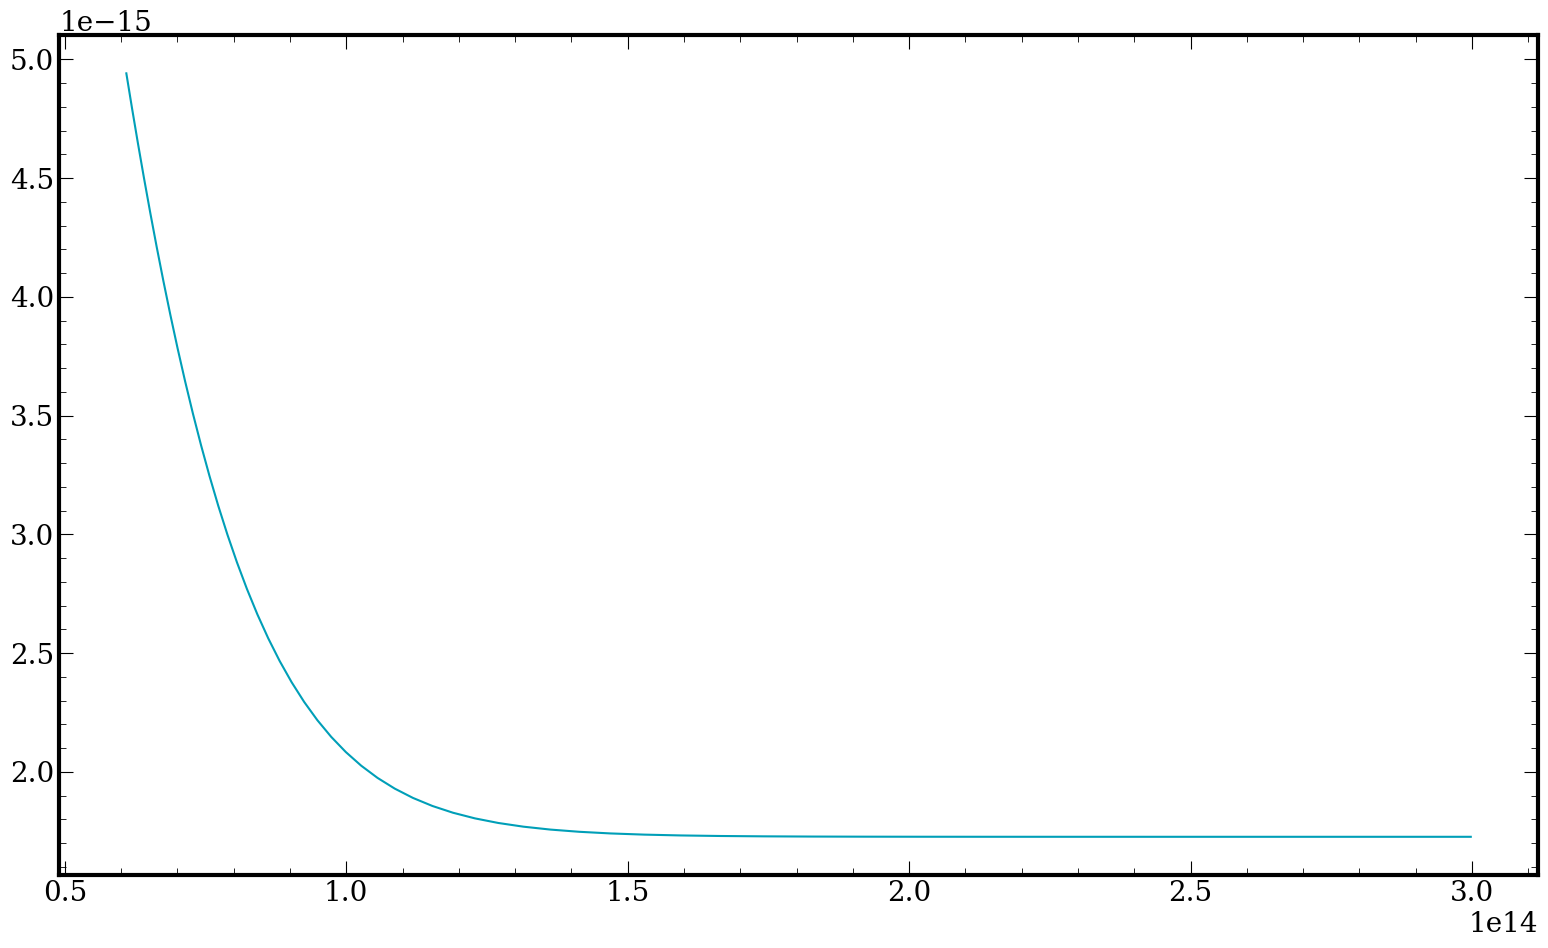

In [4]:
def jax_test_compute_feautrier_radiative_transfer_wrapper():
    """
    Tests the Python wrapper for the compute_feautrier_radiative_transfer Fortran subroutine.
    It checks for correct output shapes, types, and basic data integrity.
    """
    # Define dimensions for the test
    n_layers = 5
    n_freq_bins = 10
    n_frequencies_bin_edges = n_freq_bins + 1
    n_angles = 3  # Number of emission angles for quadrature
    n_g = 16       # Number of Gauss quadrature points for c-k opacity treatment

    # --- Create Input Arrays ---
    # Ensure float64 for Fortran double precision and Fortran memory order for f2py.

    # frequencies_bin_edges(n_frequencies_bin_edges)
    # Note: compute_planck_function_integral expects frequencies in decreasing order.
    frequencies_bin_edges = jnp.linspace(1e14, 1e13, n_frequencies_bin_edges)

    # temperatures(n_layers)
    temperatures = jnp.linspace(500., 2500., n_layers)

    # weights_gauss(n_g)
    weights_gauss = jnp.array(buffer[:,1]) # Simple equal weights

    # emission_cos_angles(n_angles)
    emission_cos_angles = jnp.array(mu_points[:,0]) # mu values

    # emission_cos_angles_weights(n_angles)
    emission_cos_angles_weights = jnp.array(mu_points[:,1])

    # optical_depths(n_g, n_freq_bins, n_layers)
    optical_depths = jnp.abs(jnp.ones((n_g, n_freq_bins, n_layers)) 
                             *jnp.logspace(-5,-3,n_g)[:,None,None]
                             *jnp.logspace(-5,-3,n_freq_bins)[None,:,None]
                             *jnp.logspace(-5,-3,n_layers)[None,None,:]).astype(jnp.float64)

    # photon_destruction_probabilities(n_g, n_freq_bins, n_layers)
    # Values typically between 1e-10 and 1.0.
    photon_destruction_probabilities = jnp.abs(jnp.ones((n_g, n_freq_bins, n_layers))*1e-5).astype(jnp.float64)
                                               #*jnp.logspace(-8,-6,n_g)[:,None,None]
                                               #*jnp.logspace(-8,-6,n_freq_bins)[None,:,None]
                                               #*jnp.logspace(-8,-6,n_layers)[None,None,:]).astype(jnp.float64)

     # emission_geometry (string)
    emission_geometry = "dayside_ave"  # Other options: 'planetary_ave', 'non-isotropic'

    # stellar_intensity(n_freq_bins)
    stellar_intensity = jnp.zeros(n_freq_bins)

    # star_irradiation_cos_angle (scalar double precision)
    star_irradiation_cos_angle = jnp.float64(1.0) # Example value

    # reflectances(n_freq_bins)
    reflectances = jnp.zeros(n_freq_bins)

    # emissivities(n_freq_bins)
    emissivities = jnp.ones(n_freq_bins)*0.1

    # return_contribution (logical)
    return_contribution = False

    # --- Call the Fortran subroutine ---
    # The f2py wrapper returns the 'intent(out)' arguments.
    # Order of arguments must match the Fortran subroutine definition.

    n_layers = 20
    n_freq_bins = 50
    n_frequencies_bin_edges = 50+1
    N_species = 2
    n_g = 16
    n_angles = 3
    wavelength_min = 1.0
    wavelength_max = 5.0
    micron_to_meter = 1e-4

    pressure_unit = 1e6
    pressures = 1e6*jnp.logspace(-6,3,N_pressures)
    frequencies_bin_edges = cst.c/(jnp.linspace(wavelength_min,wavelength_max,n_frequencies_bin_edges)*micron_to_meter)
    frequency_bin_centers = (frequency_bin_edges[:-1]+frequency_bin_edges[1:])*0.5
    temperatures = jnp.ones(pressures.shape[0])*500
    weights_gauss = jnp.array(buffer[:,1])
    emission_cos_angles = jnp.array([0.1127,0.5,0.88729])
    emission_cos_angles_weights = jnp.array([0.2777777,0.444444444,0.2777777777])
    optical_depths = jnp.ones((n_g, n_freq_bins, N_pressures))
                    # * jnp.sin(jnp.linspace(0.01,10,n_g))[:,None,None]
                    # * jnp.cos(jnp.linspace(0.1,10,n_freq_bins))[None,:,None]
                    # * jnp.sin(jnp.linspace(0.3,5,N_pressures))[None,None,:]
                    # * 1e-4)
    photon_destruction_probabilities = np.ones((n_g, n_freq_bins, N_pressures))#*1e-5* jnp.linspace(0.1,10,n_freq_bins)[None,:,None]
    emission_geometry = 'planetary_ave'
    stellar_intensity = jnp.ones(n_freq_bins)*1e-7
    star_irradiation_cos_angle = 0.5  
    reflectances = jnp.ones(n_freq_bins)*1e-7
    emissivities = jnp.ones(n_freq_bins)*1e-7
    return_contribution = False
    
    flux_out, emission_contribution_out = \
        jr.compute_feautrier_radiative_transfer(
            frequencies_bin_edges,  # (n_frequencies_bin_edges,)
            temperatures,           # (n_layers,)
            weights_gauss,          # (n_g,)
            emission_cos_angles,    # (n_angles,)
            emission_cos_angles_weights, # (n_angles,)
            optical_depths,      # (n_g, n_freq_bins, n_layers)
            photon_destruction_probabilities, # (n_g, n_freq_bins, n_layers)
            stellar_intensity,      # (n_freq_bins,)
            star_irradiation_cos_angle, # scalar
            reflectances,           # (n_freq_bins,)
            emissivities,           # (n_freq_bins,)
            # Static parameters for JIT compilation
            emission_geometry,
            return_contribution
        )
    
    plt.plot(frequencies_bin_edges[:-1], flux_out)
    # --- Assertions ---
    # Check flux output
    assert flux_out.shape == (n_freq_bins,), \
        f"Flux output shape mismatch: expected ({n_freq_bins},), got {flux_out.shape}"
    assert flux_out.dtype == np.float64, \
        f"Flux output dtype mismatch: expected np.float64, got {flux_out.dtype}"
    assert not np.any(np.isnan(flux_out)), "NaNs found in flux_out"
    assert not np.any(np.isinf(flux_out)), "Infs found in flux_out"
    # Flux should generally be non-negative for emission spectra
    assert np.all(flux_out >= -1e-9), \
        "Negative values (beyond tolerance) found in flux_out, which might be unexpected for emission."


    # Check emission_contribution output
    if return_contribution:
        assert emission_contribution_out.shape == (n_layers, n_freq_bins), \
            f"Emission contribution output shape mismatch: " \
            f"expected ({n_layers}, {n_freq_bins}), got {emission_contribution_out.shape}"
        assert emission_contribution_out.dtype == np.float64, \
            f"Emission contribution output dtype mismatch: " \
            f"expected np.float64, got {emission_contribution_out.dtype}"
        assert not np.any(np.isnan(emission_contribution_out)), \
            "NaNs found in emission_contribution_out"
        assert not np.any(np.isinf(emission_contribution_out)), \
            "Infs found in emission_contribution_out"

        # The Fortran code normalizes emission_contribution per frequency:
        # emission_contribution(:,i_freq) = emission_contribution(:,i_freq) / sum(emission_contribution(:,i_freq))
        # This implies sum should be 1.0 if the original sum was not zero (to avoid 0/0=NaN).
        if n_layers > 0 and n_freq_bins > 0:
            for i_freq in range(n_freq_bins):
                col_sum = np.sum(emission_contribution_out[:, i_freq])
                # If the sum is not zero (or very close to it), it should be normalized to 1.
                # If the sum was originally zero, it remains zero (and no NaN from 0/0).
                if not np.isclose(col_sum, 0.0, atol=1e-9):
                    assert np.isclose(col_sum, 1.0, atol=1e-5), \
                        f"Emission contribution for freq bin {i_freq} does not sum to 1 (sum={col_sum})"
                else: # If sum is close to zero, all elements in that column should be close to zero
                    assert np.all(np.isclose(emission_contribution_out[:, i_freq], 0.0, atol=1e-9)), \
                        f"Emission contribution for freq bin {i_freq} has sum ~0 but elements are not all ~0."
    else:
        # If return_contribution is False, the Fortran code still declares emission_contribution
        # as an output. f2py will likely return an array, possibly uninitialized or zeroed.
        # Check its shape and type.
        assert emission_contribution_out.shape == (n_layers, n_freq_bins)
        assert emission_contribution_out.dtype == np.float64

    print(f"\nTest test_compute_feautrier_radiative_transfer_wrapper passed with emission_geometry='{emission_geometry}'.")
    return frequencies_bin_edges[:-1], flux_out
# To run this test (e.g., if you save it as test_radtrans.py):
# pytest test_radtrans.py
frequencies, jax_flux_out = jax_test_compute_feautrier_radiative_transfer_wrapper()

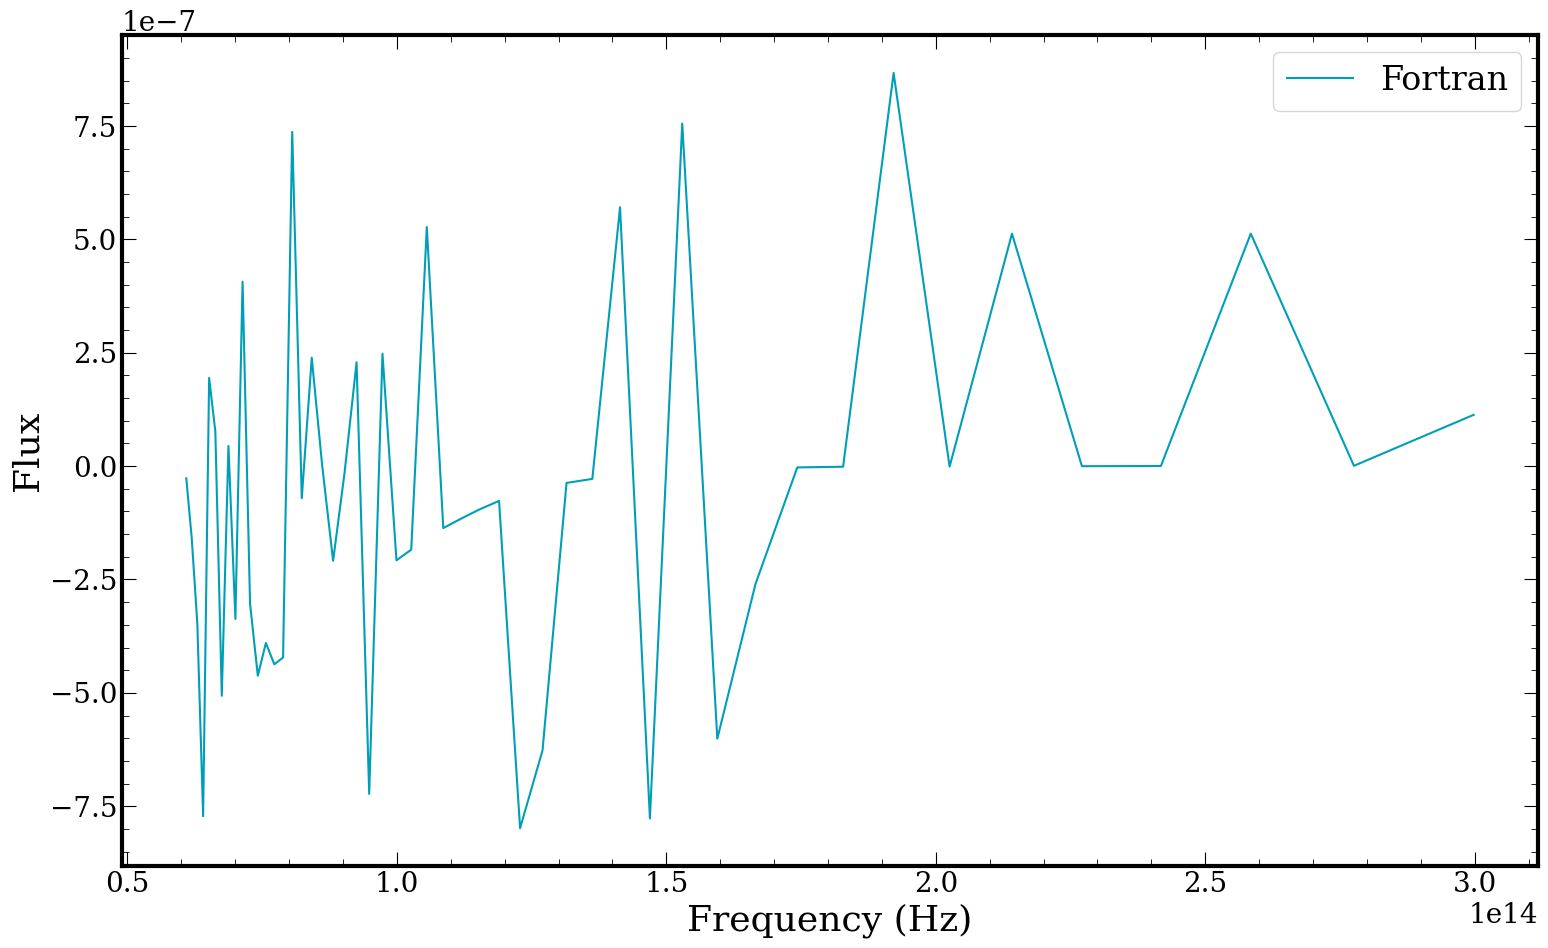

In [6]:
fig, ax = plt.subplots()
ax.plot(frequencies, (fortran_flux_out-jax_flux_out)/fortran_flux_out, label='Fortran')
#ax.plot(frequencies, jax_flux_out, label='JAX')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Flux')
ax.legend()

In [7]:
n_layers = 20
n_freq_bins = 50
n_frequencies_bin_edges = 50+1
N_species = 2
n_g = 16
n_angles = 3
wavelength_min = 1.0
wavelength_max = 5.0
micron_to_meter = 1e-4
pressure_unit = 1e6
pressures = 1e6*jnp.logspace(-6,3,N_pressures)
frequencies_bin_edges = cst.c/(jnp.linspace(wavelength_min,wavelength_max,n_frequencies_bin_edges)*micron_to_meter)
frequency_bin_centers = (frequency_bin_edges[:-1]+frequency_bin_edges[1:])*0.5
temperatures = jnp.ones(pressures.shape[0])*500
weights_gauss = jnp.array(buffer[:,1])
emission_cos_angles = jnp.array([0.1127,0.5,0.88729])
emission_cos_angles_weights = jnp.array([0.2777777,0.444444444,0.2777777777])
optical_depths = jnp.ones((n_g, n_freq_bins, N_pressures))
                # * jnp.sin(jnp.linspace(0.01,10,n_g))[:,None,None]
                # * jnp.cos(jnp.linspace(0.1,10,n_freq_bins))[None,:,None]
                # * jnp.sin(jnp.linspace(0.3,5,N_pressures))[None,None,:]
                # * 1e-4)
photon_destruction_probabilities = np.ones((n_g, n_freq_bins, N_pressures))#*1e-5* jnp.linspace(0.1,10,n_freq_bins)[None,:,None]
emission_geometry = 'planetary_ave'
stellar_intensity = jnp.ones(n_freq_bins)*1e-7
star_irradiation_cos_angle = 0.5  
reflectances = jnp.ones(n_freq_bins)*1e-7
emissivities = jnp.ones(n_freq_bins)*1e-7
return_contribution = False


In [10]:
%prun jr.compute_feautrier_radiative_transfer(frequencies_bin_edges,\
    temperatures,\
    weights_gauss,\
    emission_cos_angles,\
    emission_cos_angles_weights,\
    optical_depths,\
    photon_destruction_probabilities,\
    stellar_intensity,\
    star_irradiation_cos_angle,\
    reflectances,\
    emissivities,\
    emission_geometry,\
    return_contribution)

         2035 function calls (2010 primitive calls) in 0.101 seconds

   Ordered by: internal time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.020    0.020    0.045    0.045 pxla.py:1268(__call__)
        1    0.008    0.008    0.008    0.008 pxla.py:214(batched_device_put)
        1    0.008    0.008    0.076    0.076 pjit.py:1709(_pjit_call_impl)
        1    0.004    0.004    0.012    0.012 array.py:1133(_array_shard_arg)
        1    0.004    0.004    0.064    0.064 pjit.py:1611(_pjit_call_impl_python)
        1    0.004    0.004    0.009    0.009 pjit.py:1446(_resolve_in_layouts)
        1    0.003    0.003    0.004    0.004 pjit.py:713(_infer_params)
        6    0.003    0.001    0.005    0.001 sharding_impls.py:890(__eq__)
        1    0.003    0.003    0.003    0.003 {built-in method numpy.array}
      2/1    0.003    0.001    0.047    0.047 profiler.py:330(wrapper)
       18    0.002    0.000    0.004    0.000 array.py:537(layout)
 

In [ ]:
%prun fs.compute_feautrier_radiative_transfer(frequencies_bin_edges,\
    temperatures,\
    weights_gauss,\
    emission_cos_angles,\
    emission_cos_angles_weights,\
    optical_depths,\
    photon_destruction_probabilities,\
    stellar_intensity,\
    star_irradiation_cos_angle,\
    reflectances,\
    emissivities,\
    emission_geometry,\
    return_contribution,\
    n_frequencies_bin_edges,\
    n_layers,\
    n_angles,\
    n_g)

ValueError: 0-th dimension must be 50 but got 0 (not defined).
